In [1]:
%matplotlib widget
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ZTF_FP_Reduction import load_ztf_fp_file, ZTF_FP_Extractor

## 1. Load ZTF Forced Photometry

In [ ]:
FP_FILE = "PATH_TO_FILE"
df = load_ztf_fp_file(FP_FILE, quality_cut=True)
print(f"Loaded {len(df)} epochs  |  filters present: {df['filter'].unique()}")
df.head()

Loaded 1286 epochs  |  filters present: ['ZTF_r' 'ZTF_g' 'ZTF_i']


,index,field,ccdid,qid,filter,pid,infobitssci,sciinpseeing,scibckgnd,scisigpix,...,forcediffimsnrap,aperturecorr,dnearestrefsrc,nearestrefmag,nearestrefmagunc,nearestrefchi,nearestrefsharp,refjdstart,refjdend,procstatus
0,0,442,8,3,ZTF_r,502488763115,0,2.3537,208.7500,10.32170,...,-1.068392,1.063366,0.546095,17.561,0.059,3.456,0.226,2.458257e+06,2.458444e+06,0
1,1,442,8,3,ZTF_g,505421703115,0,2.6093,44.4963,4.61189,...,6.387162,1.100120,0.916808,18.361,0.061,4.046,0.361,2.458264e+06,2.458430e+06,0
2,2,442,8,3,ZTF_r,505462233115,0,3.0534,196.7920,5.37231,...,-1.626581,1.117869,0.546095,17.561,0.059,3.456,0.226,2.458257e+06,2.458444e+06,0
3,3,442,8,3,ZTF_g,509461143115,0,3.2807,105.4720,4.66273,...,0.827333,1.188880,0.916808,18.361,0.061,4.046,0.361,2.458264e+06,2.458430e+06,0
4,5,442,8,3,ZTF_g,513460913115,0,2.7953,106.3850,15.55150,...,1.500301,1.134101,0.916808,18.361,0.061,4.046,0.361,2.458264e+06,2.458430e+06,0


## 2. Compute Magnitudes and Plot Raw Light Curves

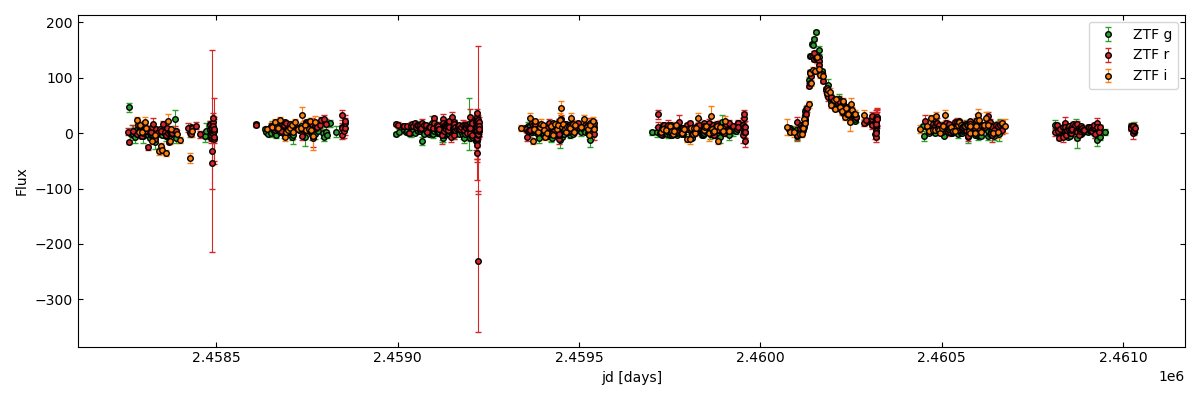

In [ ]:
obj_name = "OBJECT_NAME"
ext = ZTF_FP_Extractor(name=obj_name, df=df)
ext._set_flux_ujy_column()

fig, ax = plt.subplots(figsize=(12, 4))
ext.plot_lc(ax)
plt.tight_layout()
plt.show()

## 3. Select Baseline Window Interactively

Click and drag on the plot below to select the pre-transient baseline region.
The selected JD range is printed and stored in `ext.baseline_window`.

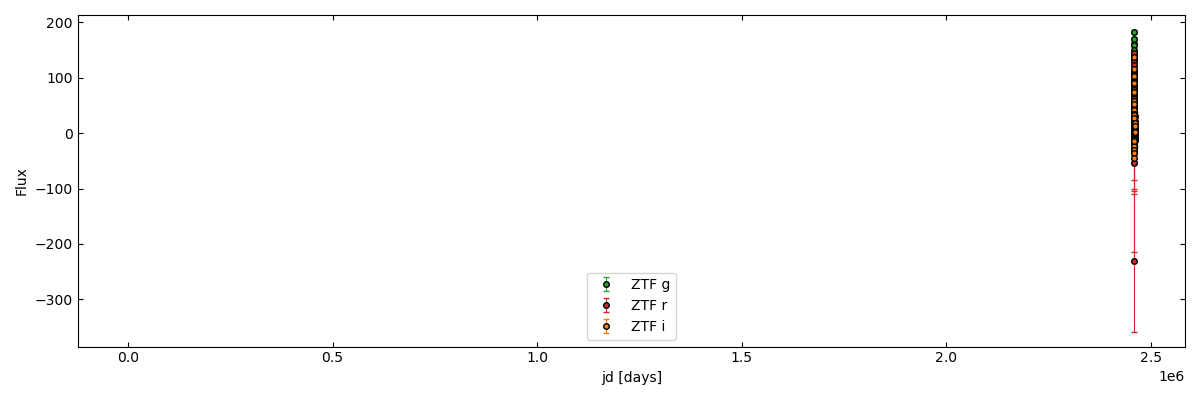

In [4]:
ext.get_baseline_window()

## 4. Apply Baseline Correction and Plot Corrected Light Curve

Baseline window: JD 2459653.1878 — 2460015.4476


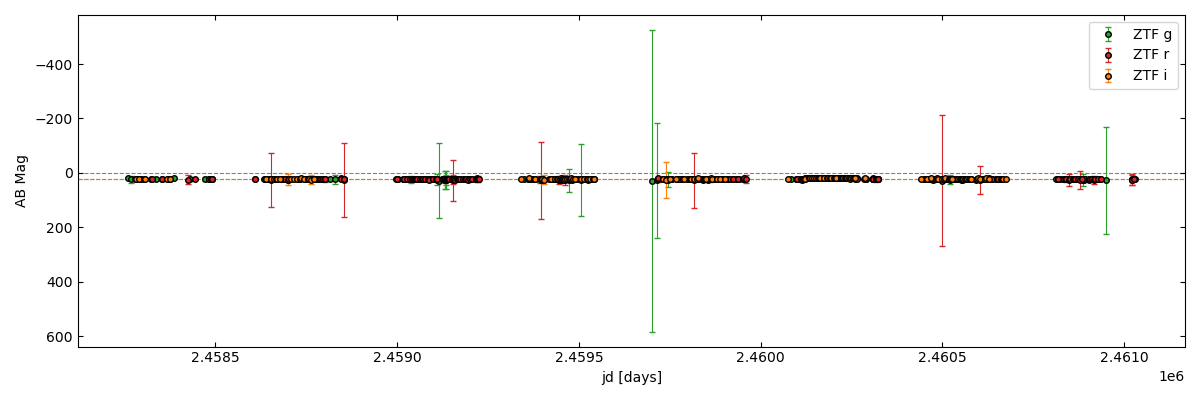

In [5]:
print(f"Baseline window: JD {ext.baseline_window[0]:.4f} — {ext.baseline_window[1]:.4f}")
ext.correct_baseline(time_window=ext.baseline_window)

fig, ax = plt.subplots(figsize=(12, 4))
ext.plot_lc(ax, plot_mag=True, use_corrected=True)
ax.axhline(0, color='gray', lw=0.8, ls='--', zorder=0)
plt.tight_layout()
plt.show()

In [ ]:
out = (
    ext.df[['jd', 'filter', 'forcediffimflux_ujy_corrected', 'forcediffimfluxunc_ujy_corrected', 'baseline_flux', 'baseline_flux_unc']]
    .dropna(subset=['forcediffimflux_ujy_corrected'])
    .reset_index(drop=True)
)
out.to_csv(f"{OBJECT_NAME}_baseline_corrected_lc.csv", index=False)
print(f"Saved {len(out)} rows to {OBJECT_NAME}_baseline_corrected_lc.csv")
out.head(10)

Saved 1286 rows to at2023mfm_baseline_corrected_lc.csv


,jd,filter,forcediffimflux_ujy_corrected,forcediffimfluxunc_ujy_corrected,baseline_flux,baseline_flux_unc
0,2.458257e+06,ZTF_r,-7.549338,6.332161,9.711162,0.502513
1,2.458260e+06,ZTF_g,44.789929,7.714932,1.816202,0.422804
2,2.458260e+06,ZTF_r,-26.501540,3.540787,9.711162,0.502513
3,2.458264e+06,ZTF_g,-3.106155,3.780153,1.816202,0.422804
4,2.458268e+06,ZTF_g,1.154676,12.376861,1.816202,0.422804
5,2.458271e+06,ZTF_r,-5.408436,11.179508,9.711162,0.502513
6,2.458271e+06,ZTF_g,-3.795115,10.771836,1.816202,0.422804
7,2.458276e+06,ZTF_g,-8.757412,10.410049,1.816202,0.422804
8,2.458279e+06,ZTF_g,4.636966,2.797830,1.816202,0.422804
9,2.458281e+06,ZTF_i,18.452703,5.879558,5.424508,0.997763
